# Loss landscapes and gradient descent

A companion to Lecture 14

Marcel Turcotte  
2026-10-27

Backpropagation computes a gradient. Whether the resulting update helps
also depends on the objective’s shape, the starting parameters, and the
learning rate. This notebook complements Lecture 14 with one-dimensional
examples that we can inspect completely.

The discussion is inspired by <a
href="https://www.youtube.com/playlist?list=PLUl4u3cNGP63URZnh5iqBzDTDYPUTQT-8"
class="external" data-icon="true">MIT 6.S191: Introduction to Deep
Learning</a>; the functions and experiments below are teaching
illustrations. A neural network usually has many parameters, so these
plots represent simplified situations rather than complete
neural-network loss surfaces.

## Following a gradient

The update is $\theta_{t+1}=\theta_t-\alpha J'(\theta_t)$. The helper
records the parameter values without clipping unless a clipping
threshold is supplied explicitly. If a deliberately nonsmooth objective
has no finite derivative at an iterate, the trace stops there.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent_1d(gradient, start, learning_rate, steps, clip_value=None):
    trajectory = [float(start)]
    for _ in range(steps):
        g = float(gradient(trajectory[-1]))
        if not np.isfinite(g):
            break  # The toy objective has no finite derivative here.
        if clip_value is not None:
            g = np.clip(g, -clip_value, clip_value)
        trajectory.append(trajectory[-1] - learning_rate * g)
    return np.asarray(trajectory)

def plot_landscape(objective, trajectory, ax, title):
    left = min(-1.2, trajectory.min())
    right = max(1.2, trajectory.max())
    padding = 0.05 * (right - left)
    theta = np.linspace(left - padding, right + padding, 800)
    ax.plot(theta, objective(theta), color='black', linewidth=1.5)
    ax.plot(trajectory, objective(trajectory), 'o-', color='#377eb8',
            markersize=3, linewidth=0.8, alpha=0.65)
    ax.scatter(trajectory[0], objective(trajectory[0]), color='#4daf4a',
               s=45, zorder=4, label='Start')
    ax.scatter(trajectory[-1], objective(trajectory[-1]), color='#d95f02',
               s=45, zorder=5, label='End')
    ax.set(title=title, xlabel=r'$\theta$', ylabel=r'$J(\theta)$')
    ax.grid(alpha=0.25)
    return theta

## Three contrasting cases

The flat-region example is
$J(\theta)=(\operatorname{ReLU}(\theta)-1)^2$. Every negative $\theta$
has loss 1 and derivative zero, yet $\theta=1$ achieves loss zero. This
is a suboptimal flat region, unlike an objective that is constant
everywhere. At zero the ordinary derivative is undefined; this example
uses the usual zero-gradient convention through ReLU.

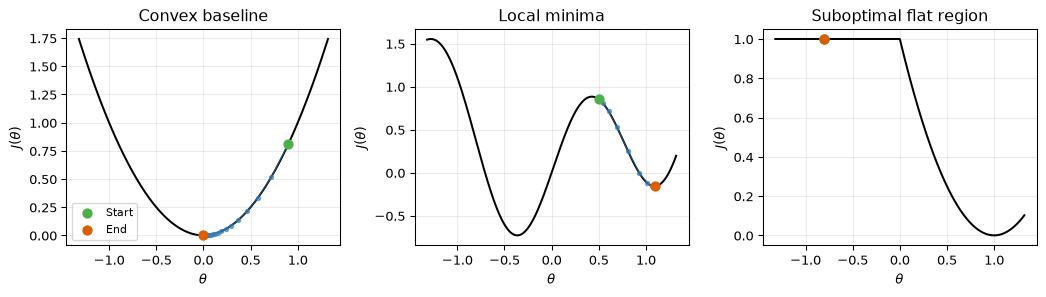

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
overview = [
    ('Convex baseline', lambda t: t**2, lambda t: 2*t, 0.9, 0.1),
    ('Local minima', lambda t: 0.8*np.sin(4*t)+0.5*t**2,
     lambda t: 3.2*np.cos(4*t)+t, 0.5, 0.05),
    ('Suboptimal flat region', lambda t: (np.maximum(0, t)-1)**2,
     lambda t: 2*(t-1) if t > 0 else 0.0, -0.8, 0.1)
]
for ax, (title, objective, gradient, start, rate) in zip(axes, overview):
    trajectory = gradient_descent_1d(gradient, start, rate, steps=60)
    plot_landscape(objective, trajectory, ax, title)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The convex example approaches its minimum. The nonconvex example reaches
a local minimum determined by its starting point. The negative initial
value in the ReLU example receives no gradient signal to escape its flat
region. A zero gradient alone does not certify a globally best
prediction rule.

In higher dimensions, a stationary point can also be a saddle: the
objective rises in some directions and falls in others. The
one-dimensional illustrations cannot display that complete geometry.

## An atlas of toy objectives

The remaining examples include a cusp, a step, and jumps to expose what
happens when ordinary differentiability fails. Networks constructed from
affine maps and continuous activations such as ReLU have continuous
predictions; the discontinuous examples below are deliberately more
pathological.

In [3]:
def cusp_gradient(theta):
    if theta == 0:
        return np.nan
    return 1.1 * np.sign(theta) / np.sqrt(abs(theta))

scenarios = [
    dict(title='Convex baseline', objective=lambda t: t**2,
         gradient=lambda t: 2*t, start=0.9, learning_rate=0.1),
    dict(title='Local minima', objective=lambda t: 0.8*np.sin(4*t) + 0.5*t**2,
         gradient=lambda t: 3.2*np.cos(4*t) + t, start=0.5, learning_rate=0.05),
    dict(title='Suboptimal flat region', objective=lambda t: (np.maximum(0, t)-1)**2,
         gradient=lambda t: 2*(t-1) if t > 0 else 0.0, start=-0.8, learning_rate=0.1),
    dict(title='Singular derivative at a cusp', objective=lambda t: 2.2*np.sqrt(np.abs(t))-1.2,
         gradient=cusp_gradient, start=0.75, learning_rate=0.05),
    dict(title='Discontinuous jump', objective=lambda t: np.where(t < 0, 0.5*t-0.2, 0.5*t+0.6),
         gradient=lambda t: 0.5 if t != 0 else np.nan, start=0.8, learning_rate=0.1),
    dict(title='Several local minima', objective=lambda t: 0.5*np.cos(2*np.pi*t) + 0.25*t**2,
         gradient=lambda t: -np.pi*np.sin(2*np.pi*t) + 0.5*t, start=0.6, learning_rate=0.01),
    dict(title='Step objective', objective=lambda t: np.where(t >= 0, 0.5, -0.5),
         gradient=lambda t: 0.0 if t != 0 else np.nan, start=0.7, learning_rate=0.1),
    dict(title='Opposing slopes with a jump', objective=lambda t: np.where(t < 0, -t-0.2, t+0.4),
         gradient=lambda t: -1.0 if t < 0 else (1.0 if t > 0 else np.nan),
         start=0.8, learning_rate=0.15)
]

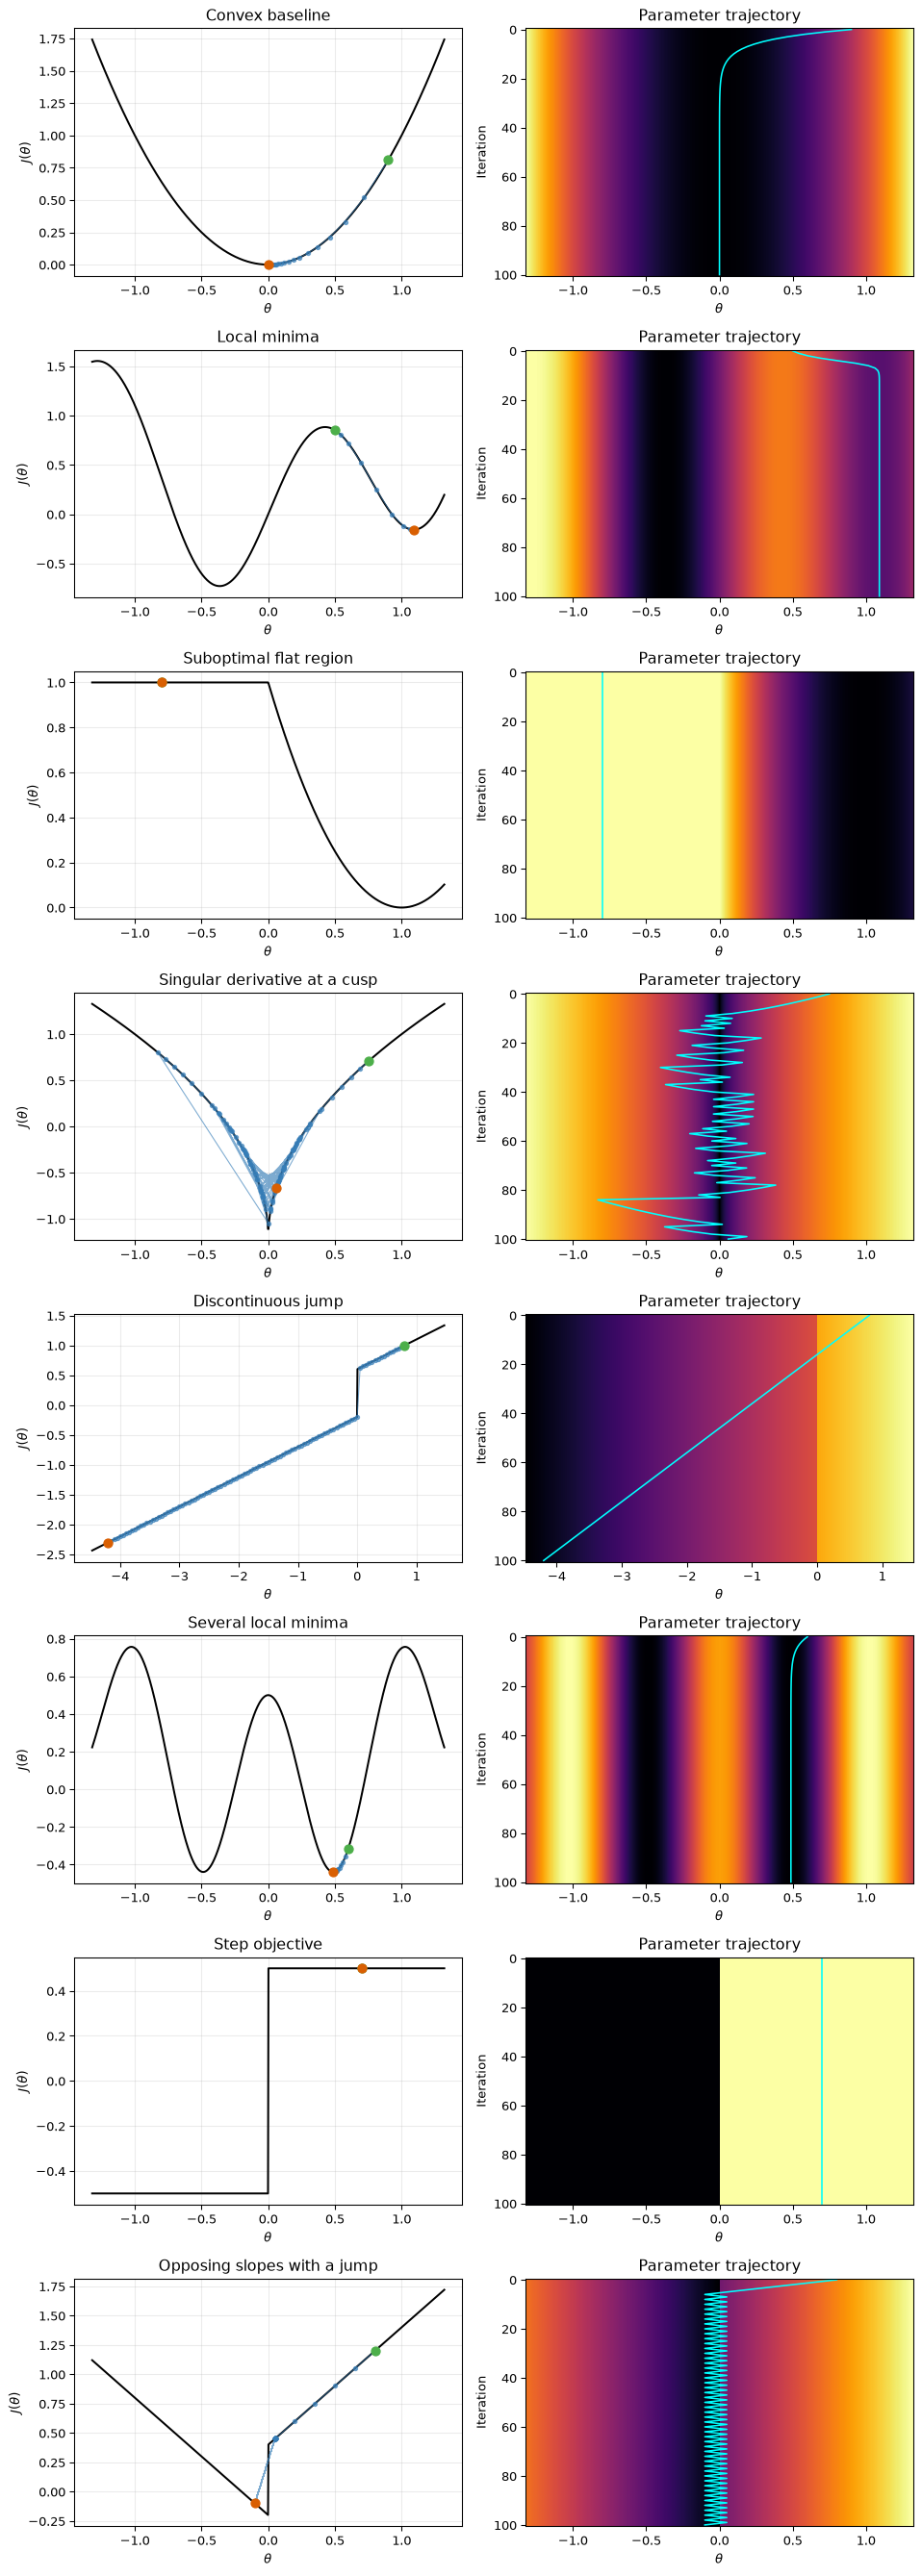

In [4]:
fig, axes = plt.subplots(len(scenarios), 2, figsize=(10, 3.5*len(scenarios)))
for index, scenario in enumerate(scenarios):
    row, column = index, 0
    trajectory = gradient_descent_1d(scenario['gradient'], scenario['start'],
                                     scenario['learning_rate'], steps=100)
    theta = plot_landscape(scenario['objective'], trajectory, axes[row, column],
                           scenario['title'])
    iterations = np.arange(len(trajectory))
    values = np.broadcast_to(scenario['objective'](theta), (len(iterations), len(theta)))
    axes[row, column+1].pcolormesh(theta, iterations, values,
                                   cmap='inferno', shading='auto')
    axes[row, column+1].plot(trajectory, iterations, color='cyan', linewidth=1.2)
    axes[row, column+1].invert_yaxis()
    axes[row, column+1].set(title='Parameter trajectory', xlabel=r'$\theta$', ylabel='Iteration')
fig.tight_layout()
plt.show()

Each heatmap repeats the **same fixed one-dimensional objective** down
the page. Its horizontal axis is the parameter; its vertical axis is
iteration. It is not a two-parameter loss surface. Plot limits include
the recorded trajectory, including excursions beyond the initial
interval.

The jump objective with a constant positive slope is unbounded below.
The opposing-slopes example has an unattained lower limiting value as
zero is approached from the left. These examples illustrate broken
optimization assumptions, not a claim that ordinary neural losses always
have these properties.

The cusp has an unbounded derivative near zero, where the derivative is
undefined. This is a **singular local derivative**. Exploding gradients
in a deep network can instead arise from multiplying transformations
during backpropagation; no individual activation derivative needs to be
singular.

## Gradient clipping on a steep objective

Use $J(\theta)=20\theta^2$, with $J'(\theta)=40\theta$. At learning rate
$\alpha=0.08$, the unclipped update multiplies the current value by
$-2.2$, so its magnitude grows. Clipping the scalar gradient to $[-5,5]$
limits each update’s magnitude to $0.4$.

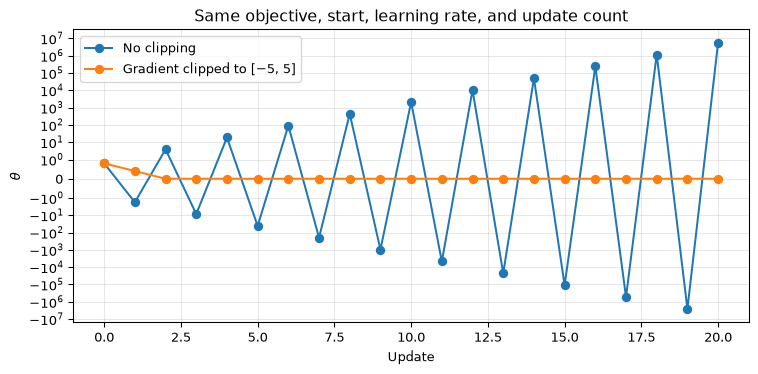

In [5]:
steep_objective = lambda t: 20*t**2
steep_gradient = lambda t: 40*t
unclipped = gradient_descent_1d(steep_gradient, 0.8, 0.08, steps=20)
clipped = gradient_descent_1d(steep_gradient, 0.8, 0.08, steps=20, clip_value=5.0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(unclipped, 'o-', label='No clipping')
ax.plot(clipped, 'o-', label='Gradient clipped to [−5, 5]')
ax.set_yscale('symlog', linthresh=1)
ax.set(xlabel='Update', ylabel=r'$\theta$', title='Same objective, start, learning rate, and update count')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

The symmetric logarithmic axis displays large positive and negative
values while retaining the region around zero. Clipping bounds the step;
choosing a smaller learning rate would also address this quadratic
example. In a network, global-norm clipping rescales a gradient vector
when its norm exceeds a threshold.

## Clipping is not a convergence guarantee

The square-root cusp provides a counterexample: clipping can leave a
fixed-step method oscillating near the minimum. Compare both traces with
identical settings.

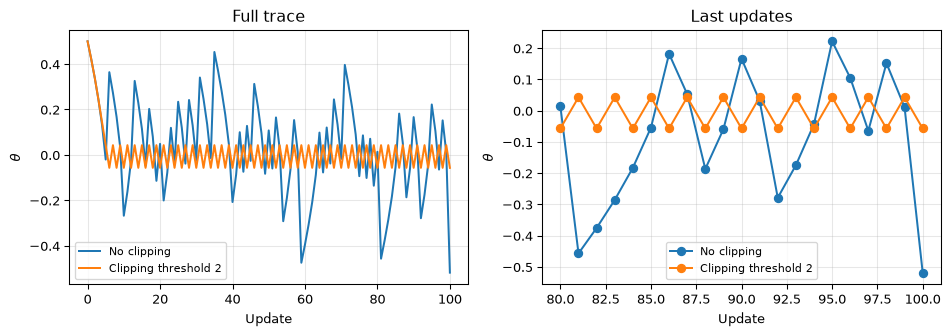

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for threshold, label in [(None, 'No clipping'), (2.0, 'Clipping threshold 2')]:
    trajectory = gradient_descent_1d(cusp_gradient, 0.5, 0.05, steps=100,
                                     clip_value=threshold)
    axes[0].plot(trajectory, label=label)
    axes[1].plot(np.arange(80, len(trajectory)), trajectory[80:], 'o-', label=label)
axes[0].set(title='Full trace', xlabel='Update', ylabel=r'$\theta$')
axes[1].set(title='Last updates', xlabel='Update', ylabel=r'$\theta$')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Bounded updates need not approach a minimizer. The learning rate and its
schedule still matter. Clipping does not restore a gradient that has
vanished, remove local minima, or make a discontinuous objective
differentiable.

For reflection: which traces stop because their gradients are zero,
which depend on the starting value, and which fail because the update is
too large?

[Return to Lecture 14](index.qmd).